<a href="https://colab.research.google.com/github/RobertoSonzini/NAML_project/blob/main/Progetto_NAML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Progetto NAML**

## **Project Overview**

SPIEGAZIONE CONCETTI LSTM, GAN e PRINCIPI

In [56]:
!pip uninstall torch
!pip cache purge
!pip install torch --upgrade

Files removed: 68
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 821.2/821.2 MB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 393.1/393.1 MB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 94.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 36.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.7/897.7 kB 47.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 571.0/571.0 MB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.2/200.2 MB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 62.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 158.2/158.2 MB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.6/216.6 MB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 156.8/156.8 MB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
import torch
from torch import nn
import math
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

In [2]:
# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## **Dataset study**

DOBBIAMO PULIRE IL DATASET: TOGLIERE NULLI (nel metodo per ottenere un sotto-dataset l'ho già implementato) E VEDERE SE ABBIAMO OUTSIDERS (NEL CASO POSSIAMO VEDERE COSA SUCCEDE E SE HANNO IMPATTO).
DOBBIAMO VEDERE ANCHE SE SCALARE/NORMALIZZARE I DATI?

In [3]:
!pip install tensorflow

In [4]:
file_path = '/content/drive/MyDrive/ProgettoNAML/all_stocks_5yr.csv'
drive.mount('/content/drive')

df = pd.read_csv(file_path)
df.head()

%matplotlib inline

from datetime import datetime

df.info()
df

Mounted at /content/drive
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619040 entries, 0 to 619039
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    619040 non-null  object 
 1   open    619029 non-null  float64
 2   high    619032 non-null  float64
 3   low     619032 non-null  float64
 4   close   619040 non-null  float64
 5   volume  619040 non-null  int64  
 6   Name    619040 non-null  object 
dtypes: float64(4), int64(1), object(2)
memory usage: 33.1+ MB


,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL
...,...,...,...,...,...,...,...
619035,2018-02-01,76.84,78.27,76.69,77.82,2982259,ZTS
619036,2018-02-02,77.53,78.12,76.73,76.78,2595187,ZTS
619037,2018-02-05,76.64,76.92,73.18,73.83,2962031,ZTS
619038,2018-02-06,72.74,74.56,72.13,73.27,4924323,ZTS


In [5]:
latest_date = pd.to_datetime(df['date']).max()

one_year_before = latest_date - pd.DateOffset(years=1)

date_series = pd.to_datetime(df['date'])
mask = (date_series >= one_year_before) & (date_series <= latest_date) & (df['Name'] == 'AAPL')

filtered_df = df[mask]
filtered_df['date'] = pd.to_datetime(filtered_df['date'])

/tmp/ipython-input-5-1817002058.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df['date'] = pd.to_datetime(filtered_df['date'])


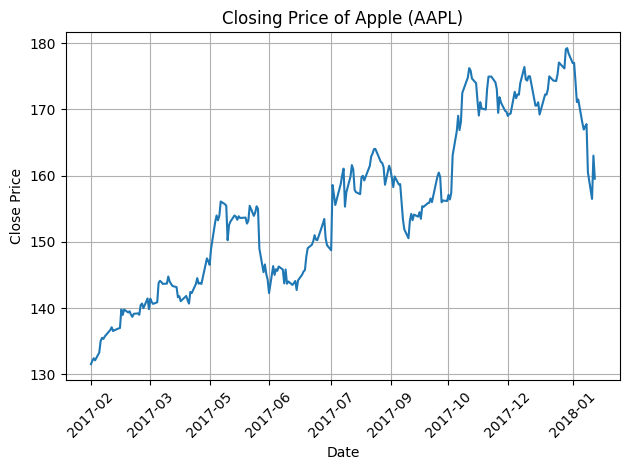

In [6]:
plt.plot(filtered_df['date'], filtered_df['close'])
plt.ylabel('Close Price')
plt.xlabel('Date')
plt.title("Closing Price of Apple (AAPL)")

# Mostra solo una data ogni 30 giorni (puoi cambiare questo intervallo)
step = 30

# Usa xticks per visualizzare solo alcune date
plt.xticks(ticks=filtered_df['date'][::step], labels=filtered_df['date'].dt.strftime('%Y-%m')[::step], rotation=45)

plt.grid(True)
plt.tight_layout()

plt.show()

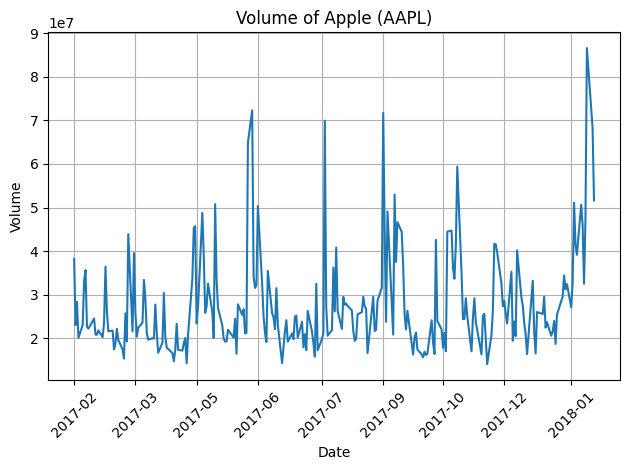

In [7]:
plt.plot(filtered_df['date'], filtered_df['volume'])
plt.ylabel('Volume')
plt.xlabel('Date')
plt.title("Volume of Apple (AAPL)")

# Mostra solo una data ogni 30 giorni (puoi cambiare questo intervallo)
step = 30

# Usa xticks per visualizzare solo alcune date
plt.xticks(ticks=filtered_df['date'][::step], labels=filtered_df['date'].dt.strftime('%Y-%m')[::step], rotation=45)

plt.grid(True)
plt.tight_layout()

plt.show()

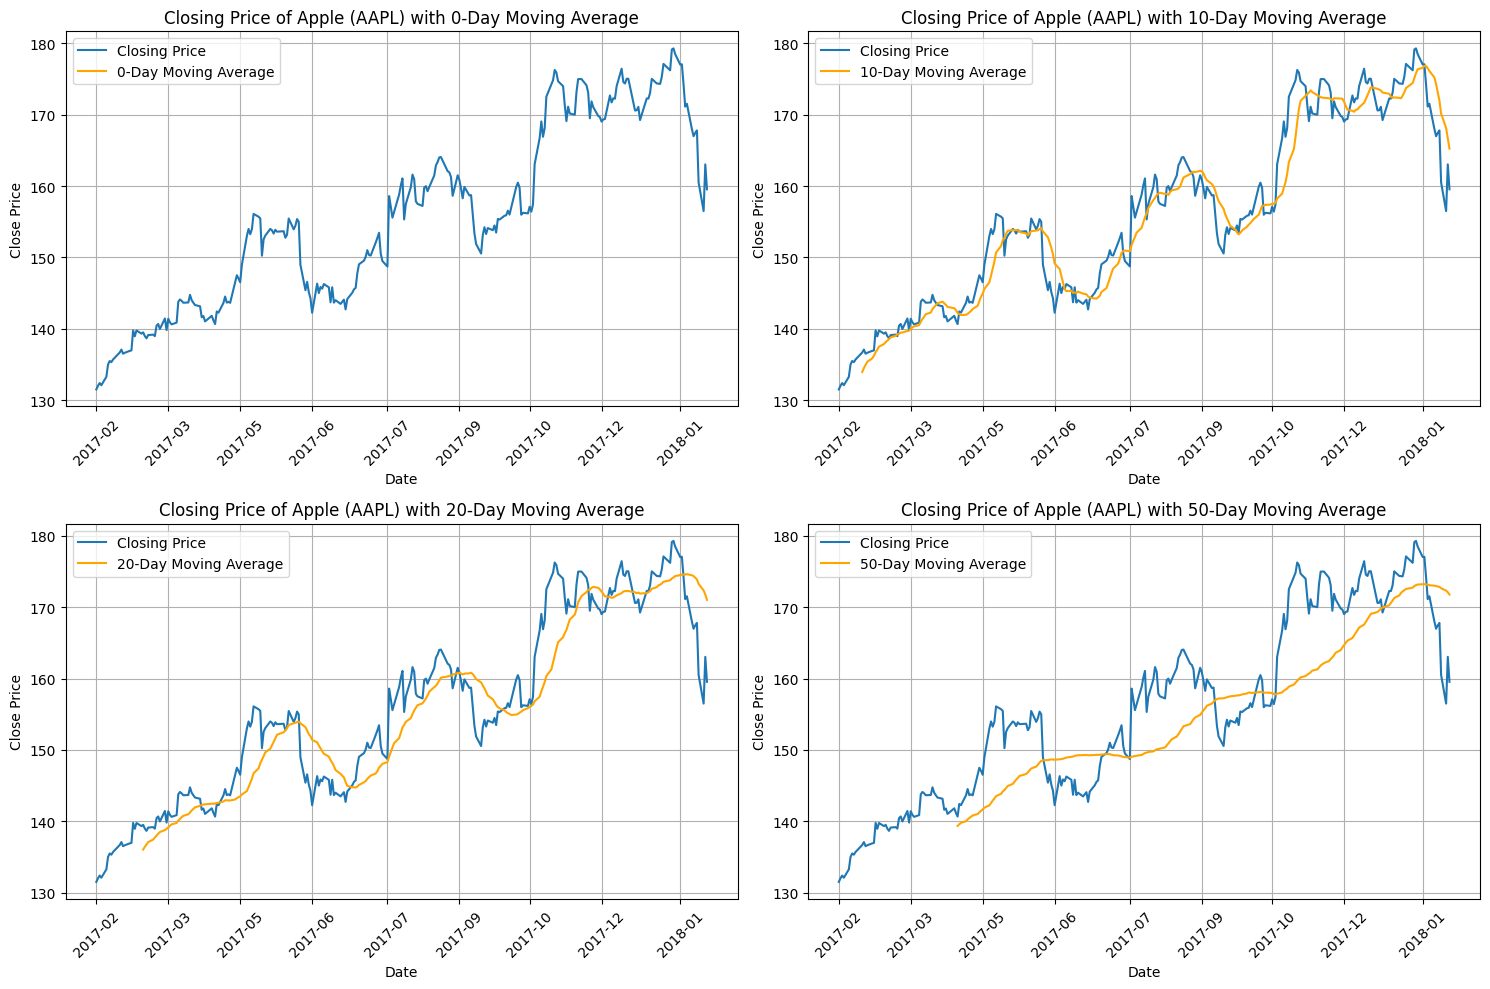

In [8]:
import matplotlib.pyplot as plt

ma_day = [0, 10, 20, 50]  # Diversi periodi per la media mobile
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))  # Creazione di una figura 2x2

# Ciclo per calcolare e tracciare la media mobile per ciascun valore di 'ma'
for i, ma in enumerate(ma_day):
    # Crea una copia del dataset per ogni 'ma'
    df_copy = filtered_df.copy()
    df_copy['ma_close'] = df_copy['close'].rolling(ma).mean()

    # Seleziona l'asse per il grafico
    ax = axes[i // 2, i % 2]  # Seleziona l'asse giusto (2 righe, 2 colonne)

    # Plot del prezzo di chiusura
    ax.plot(df_copy['date'], df_copy['close'], label='Closing Price')

    # Plot della media mobile
    ax.plot(df_copy['date'], df_copy['ma_close'], label=f'{ma}-Day Moving Average', color='orange')

    # Aggiungi etichette, titolo e legenda
    ax.set_ylabel('Close Price')
    ax.set_xlabel('Date')
    ax.set_title(f"Closing Price of Apple (AAPL) with {ma}-Day Moving Average")
    ax.legend()

    # Mostra solo alcune date sull'asse X
    step = 30
    ax.set_xticks(df_copy['date'][::step])
    ax.set_xticklabels(df_copy['date'].dt.strftime('%Y-%m')[::step], rotation=45)

    # Mostra la griglia
    ax.grid(True)

# Ottimizza la visualizzazione
plt.tight_layout()
plt.show()

## **Network setup**

### **Training dataset setup**

In [9]:
# Facciamo una split del dataset per avere training, validation (vediamo poi se e come usarlo) e test set.
'''
  1. decidere che dati utilizzare
  2. vettore 'input data' usato dal paper: [high_price, low_price, open_price, close_price, volume, turnover_rate, Ma(5)]
'''

"\n  1. decidere che dati utilizzare\n  2. vettore 'input data' usato dal paper: [high_price, low_price, open_price, close_price, volume, turnover_rate, Ma(5)]\n"

In [10]:
df.head()

,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL


#### **Step 1) select a single company and complete the dataset**

*We filter our dataset to have data of the company "APPLE" and we compute the MA(5)*

In [11]:
def sort_by_date(df):
  return df.sort_values(by='date')

In [12]:
def get_dataframe(df, company_names, moving_average=5):
    input_data_labels = ['high', 'low', 'open', 'volume', 'ma5']
    close_data = ['close']

    mask = df['Name'].isin(company_names)
    df_company = df.loc[mask].copy()

    df_company['ma5'] = df_company['close'].rolling(moving_average).mean()

    df_company = df_company.dropna()

    df_company = sort_by_date(df_company)

    return df_company[input_data_labels], df_company[close_data]

In [13]:
df_apple, apple_closings = get_dataframe(df, ['AAPL'])
df_apple.head()

,high,low,open,volume,ma5
1263,67.3771,66.2885,66.3599,88809154,67.32592
1264,67.1656,65.7028,66.9785,97924631,66.90250
1265,66.1042,64.8356,65.8714,108854046,66.33278
1266,65.3842,64.1142,65.3842,118891367,65.78850
1267,64.1671,63.2599,63.7142,111596821,65.18994


In [14]:
df_apple.shape[0]

1255

##### **Analysis of dataset size per individual company**

In [15]:
company_sizes = {}
companies = df['Name'].unique()

for company in companies:
  df_company, company_closings = get_dataframe(df, [company])
  company_sizes[company] = df_company.shape[0]

In [16]:
key_max = max(company_sizes, key=company_sizes.get)
val_max = company_sizes[key_max]

key_min = min(company_sizes, key=company_sizes.get)
val_min = company_sizes[key_min]

# Output
print(f"MAX → {key_max}: {val_max}")
print(f"MIN → {key_min}: {val_min}")

MAX → AAL: 1255
MIN → APTV: 40


#### **Splitting the dataset**

MI MANCA DA SEPARARE LE LABELS (RIFERIMENTO AL CLOSING PRICE)

In [237]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# prendo nuovamente i dati

df_company, company_closings = get_dataframe(df, ['AAPL'])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

In [238]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(1129, 5)
(1129, 1)
(126, 5)
(126, 1)


### **Discriminator and Generator**

In [239]:
class Discriminator(nn.Module):
  '''
    From paper:
      Here, we choose an MLP as our discriminator with three hidden layers h1,h2,h3 including 72, 100, 10 neurons, respectively.
      The Leaky ReLU is used as the activation function among the hidden layers and the sigmoid function is used in the output layer.

      Cose da notare / considerare:
        - Dato che stiamo usando un MLP, vuoi un input a forma di vettore, però nel paper viene usato un input che prevede più samples.
          In particolare costruisce una matrice X formata da (t + 1) time steps (presi dai dati reali).
          I primi t valori saranno presi dal dattaset, mentre l'ultimo verrà o generato dal generatore, oppure preso anch'esso dal dataset reale.

        - A seguito di quanto detto nel punto prima, sarà anche da considerare l'ampiezza dell'intervallo di time steps come hyperparameter.

        - Andrà anche considerato che nel nostrto dataset, non abbiamo un dato per ogni giorno specifico.
          Potrebbe essere sensato kl non considare questo aspetto poichè alla fine non poniamo le date come un input utile.
          Se volessimo però avere una predizione che considera la data, cioè vogliamo considerare anche che c'è una dipendenza dagli effetivi giorni che separano un sample al tempo t e al tempo t+1,
            dovremmo intervenire in qualche modo.
          (da notare che attualmente le moving average non tengono conto di questo)

        - Come gestiamo la differenza dimensionale tra gli input?
          Soluzione 1: Usiamo un reshape che rende unidimensionale la matrice concatenando un sample dietro l'altro
  '''

  '''
    seq_len: la sequence size
    t_features: è il numero di features per ogni sample.
  '''
  def __init__(self, seq_len, n_features = 1):
    super().__init__()
    self.n_features = n_features
    self.seq_len = seq_len

    input_dim = self.seq_len * self.n_features
    self.model = nn.Sequential(

    # The input is two-dimensional (perchè ho un MLP), and the first hidden layer is composed of 256 neurons with ReLU activation.
    # The second and third hidden layers are composed of 128 and 64 neurons, respectively, with ReLU activation.
    # The output is composed of a single neuron with sigmoidal activation to represent a probability. <---
    # After the first, second, and third hidden layers, you use dropout to avoid overfitting.

      nn.Linear(input_dim, 72),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(72, 100),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(100, 10),
      nn.LeakyReLU(),
      nn.Dropout(0.3),
      nn.Linear(10, 1),
      nn.Sigmoid(),
    )

  # You use .forward() to describe how the output of the model is calculated.
  # Here, x represents the input of the model, which is a two-dimensional tensor.
  # In this implementation, the output is obtained by feeding the input x to the model you’ve defined without any other processing.

  def forward(self, x):
    # x shape attesa: (batch_size, t_input, n_features)
    # Flatten temporale e feature dimensioni → (batch_size, t_input * n_features)
    # print(f"From discriminator (input_shape): {x.shape}")
    X_flat = x.view(x.size(0), -1)
    # print(f"From discriminator (X_flat_shape): {X_flat.shape}")
    return self.model(X_flat)

In [240]:
class GeneratorLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, seq_len):
      '''
        * input_size – The number of expected features in the input x
        * hidden_size – The number of features in the hidden state h (dimensione hidden layer della lstm -> non dipende dai nostri dati, ma è un hyperparameter)
        * num_layers – Number of recurrent layers. (a quanto parre quantti strati di LSTM usiamo)
          E.g., setting num_layers=2 would mean stacking two LSTMs together to form a stacked LSTM, with the second LSTM taking in outputs of the first LSTM and computing the final results. Default: 1

        * bias – If False, then the layer does not use bias weights b_ih and b_hh. Default: True
        * batch_first – If True, then the input and output tensors are provided as (batch, seq, feature) instead of (seq, batch, feature). Note that this does not apply to hidden or cell states. See the Inputs/Outputs sections below for details. Default: False
        * dropout – If non-zero, introduces a Dropout layer on the outputs of each LSTM layer except the last layer, with dropout probability equal to dropout. Default: 0
        * bidirectional – If True, becomes a bidirectional LSTM. Default: False
        * proj_size – If > 0, will use LSTM with projections of corresponding size. Default: 0
      '''
      super(GeneratorLSTM, self).__init__()
      self.num_layers = num_layers
      self.hidden_size = hidden_size
      self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.3)
      self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
      # -> x needs to be: (batch_size, seq_len, input_size)
      # Set initial hidden states (and cell states for LSTM)
      h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)
      c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)

      # Forward propagate LSTM
      out, _ = self.lstm(x, (h0,c0))

      # out: tensor of shape (batch_size, seq_len, hidden_size)

      # Decode the hidden state of the last time step
      out = out[:, :, :]
      out = self.fc(out)

      return out

### **Training**

In [241]:
from torch.utils.data import Dataset

class MyGANDataset(Dataset):
    def __init__(self, X_data, y_data, seq_len = 1):
      self.X_data = X_data  # array, tensor o lista di feature
      self.y_data = y_data  # target (opzionale se inferenza)
      self.seq_len = seq_len

    def __len__(self):
      return len(self.y_data) - self.seq_len

    def __getitem__(self, idx):
      x = self.X_data[idx : idx + self.seq_len]
      y = self.y_data[idx : idx + self.seq_len] # il target qui lo prendo solo sul passo successivo (last step)

      # x_tensor = torch.tensor(x)
      # y_tensor = torch.tensor(y)

      return x, y

In [242]:
# per esempio di utilizzo

from torch.utils.data import DataLoader

datasetGAN = MyGANDataset(X_train, y_train, seq_len = 10)
loader = DataLoader(datasetGAN, batch_size=32, shuffle=False)

In [243]:
# per debug, lascio questa stampa dei batch creati automaticamente dal dataloader
for i, (x_batch, y_batch) in enumerate(loader):
    print(f"Batch {i+1}: {x_batch.size}")
    print("x_batch shape:", x_batch.shape)
    print("y_batch shape:", y_batch.shape)
    print("-" * 30)
    if i == 0:
        break

Batch 1: <built-in method size of Tensor object at 0x79fb329df050>
x_batch shape: torch.Size([32, 10, 5])
y_batch shape: torch.Size([32, 10, 1])
------------------------------


In [244]:
def get_fake_labels(real_labels, output_LSTM):
  # real_labels (batch_size, seq_len, 1)
  # output_LSTM (batch_size, seq_len, 1)

  last_step_output = output_LSTM[:, -1, :]

  y_fake = real_labels.clone()
  y_fake[:, -1, :] = last_step_output

  return y_fake

In [245]:
generator = GeneratorLSTM(input_size=5, hidden_size=32, num_layers=1, seq_len=10)
x_batch, y_batch = next(iter(loader))
outputs = generator(x_batch)
print(outputs.shape)

torch.Size([32, 10, 1])


/usr/local/lib/python3.11/dist-packages/torch/nn/modules/rnn.py:123: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.3 and num_layers=1
  warnings.warn(


In [246]:
y_batch[0]

tensor([[-1.3947],
        [-1.4249],
        [-1.4257],
        [-1.4778],
        [-1.4909],
        [-1.4686],
        [-1.5062],
        [-1.4773],
        [-1.4979],
        [-1.5127]])

In [247]:
get_fake_labels(y_batch, outputs)[0]

tensor([[-1.3947],
        [-1.4249],
        [-1.4257],
        [-1.4778],
        [-1.4909],
        [-1.4686],
        [-1.5062],
        [-1.4773],
        [-1.4979],
        [ 0.0625]], grad_fn=<SelectBackward0>)

In [249]:
import torch.nn.functional as F

def discriminator_loss(D_real, D_fake):
    # Small epsilon to prevent log(0)
    loss = -torch.mean(torch.log(D_real) + torch.log(1 - D_fake))
    return loss

def generator_loss(D_fake, output_LSTM, y_real, lambda1=0.7, lambda2=0.3):
    # MSE component
    mse_loss = F.mse_loss(output_LSTM, y_real)

    # Adversarial gloss component
    adv_loss = torch.mean(torch.log(1 - D_fake))

    # Total generator loss
    return lambda1 * mse_loss + lambda2 * adv_loss

In [250]:
def train_GAN(
    generator,
    discriminator,
    learning_rate_discriminator,
    learning_rate_generator,
    epochs,
    generator_loss,
    discriminator_loss,
    generator_optimizer,
    discriminator_optimizer,
    seq_len,
    batch_size = 32):

  dataset_real = MyGANDataset(X_train, y_train, seq_len = seq_len)
  loader = DataLoader(dataset_real, batch_size=batch_size, shuffle=False)
  n_total_steps = len(loader)

  for epoch in range(epochs):
    for i, (samples, labels) in enumerate(loader):
      X_real = samples.to(device)
      y_real = labels.to(device)

      # print(f"y_real shape: {y_real.shape}")

      output_LSTM = generator(X_real)
      y_fake = get_fake_labels(y_real, output_LSTM)

      # print(f"y-fake shape: {y_fake.shape}")

      # Training the discriminator
      discriminator.zero_grad() # In PyTorch, it’s necessary to clear the gradients at each training step to avoid accumulating them. You do this using .zero_grad()
      output_discriminator_real = discriminator(y_real)
      output_discriminator_fake = discriminator(y_fake)

      loss_discriminator = discriminator_loss(
        output_discriminator_real, output_discriminator_fake)

      # You calculate the gradients to update the weights with loss_discriminator.backward()
      loss_discriminator.backward()
      # You update the discriminator weights by calling optimizer_discriminator.step()
      discriminator_optimizer.step()

      # Training the generator
      generator.zero_grad()

      output_LSTM = generator(X_real)
      y_fake = get_fake_labels(y_real, output_LSTM)

      output_discriminator_generated = discriminator(y_fake)

      # You calculate the loss function using the output of the classification system stored in output_discriminator_generated and the labels in real_samples_labels, which are all equal to 1.
      loss_generator = generator_loss(
        output_discriminator_generated, output_LSTM, y_real
      )
      loss_generator.backward()
      generator_optimizer.step()

    # Show loss
    if epoch % 50 == 0:
      print(f"Epoch: {epoch} Loss D.: {loss_discriminator}")
      print(f"Epoch: {epoch} Loss G.: {loss_generator}")

In [251]:
# hyperparameters
input_size = 5
hidden_size = 32
num_layers = 1
num_epochs = 500
lr = 0.001
seq_len = 40

generator = GeneratorLSTM(input_size, hidden_size, num_layers, seq_len)
discriminator = Discriminator(seq_len)
generator_optimizer = torch.optim.Adam(generator.parameters(), lr=lr)
discriminator_optimizer = torch.optim.Adam(discriminator.parameters(), lr=lr)

In [252]:
train_GAN(
    generator,
    discriminator,
    lr,
    lr,
    num_epochs,
    generator_loss,
    discriminator_loss,
    generator_optimizer,
    discriminator_optimizer,
    seq_len)

Epoch: 0 Loss D.: 1.3528393507003784
Epoch: 0 Loss G.: 0.5593810081481934
Epoch: 50 Loss D.: 1.3872318267822266
Epoch: 50 Loss G.: -0.20357783138751984
Epoch: 100 Loss D.: 1.3915289640426636
Epoch: 100 Loss G.: -0.20526938140392303
Epoch: 150 Loss D.: 1.3940752744674683
Epoch: 150 Loss G.: -0.20859023928642273
Epoch: 200 Loss D.: 1.3838703632354736
Epoch: 200 Loss G.: -0.20712801814079285
Epoch: 250 Loss D.: 1.385807991027832
Epoch: 250 Loss G.: -0.20830664038658142
Epoch: 300 Loss D.: 1.3928545713424683
Epoch: 300 Loss G.: -0.20636078715324402
Epoch: 350 Loss D.: 1.4032933712005615
Epoch: 350 Loss G.: -0.20481082797050476
Epoch: 400 Loss D.: 1.1374949216842651
Epoch: 400 Loss G.: -0.17673425376415253
Epoch: 450 Loss D.: 1.3902159929275513
Epoch: 450 Loss G.: -0.2097538858652115


In [253]:
def test_GAN(model, seq_len, loss_function):
  model.eval()
  total_loss = 0
  preds = []
  actuals = []

  dataset = MyGANDataset(X_test, y_test, seq_len = seq_len)
  loader = DataLoader(dataset, batch_size=32, shuffle=False)

  with torch.no_grad():
    for i, (x_batch, y_batch) in enumerate(loader):
      x_batch = x_batch.to(device)
      y_batch = y_batch.to(device)

      outputs = model(x_batch)
      last_step_output = outputs[:, -1, :]

      last_step_label = y_batch[:, -1, :]

      loss = loss_function(last_step_output, last_step_label)

      total_loss += loss.item() * x_batch.size(0)

      preds.extend(last_step_output.cpu().numpy())
      actuals.extend(last_step_label.cpu().numpy())

  avg_loss = total_loss / len(loader.dataset)
  print(f"Test Loss: {avg_loss:.4f}")

  return preds, actuals

In [260]:
preds_GAN, actuals_GAN = test_GAN(generator, seq_len, nn.MSELoss())

Test Loss: 0.0010


In [261]:
def plot_predictions(preds, actuals):
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

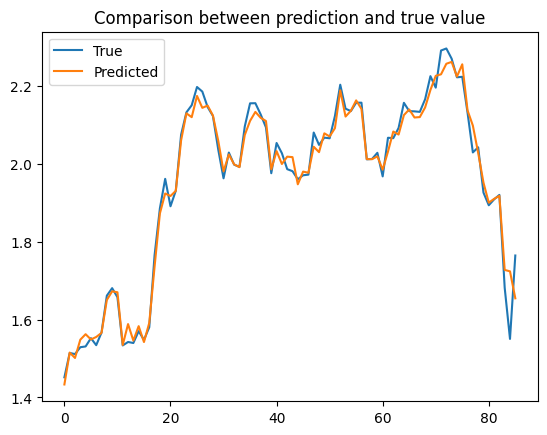

In [262]:
plot_predictions(preds_GAN, actuals_GAN)

## **General LSTM**

In [26]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# prendo nuovamente i dati

df_company, company_closings = get_dataframe(df, ['AAPL'])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

In [27]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(1129, 5)
(1129, 1)
(126, 5)
(126, 1)


In [28]:
from torch.utils.data import Dataset

class MyDataset(Dataset):
    def __init__(self, X_data, y_data, seq_len = 1):
      self.X_data = X_data  # array, tensor o lista di feature
      self.y_data = y_data  # target (opzionale se inferenza)
      self.seq_len = seq_len

    def __len__(self):
      return len(self.y_data) - self.seq_len

    def __getitem__(self, idx):
      x = self.X_data[idx : idx + self.seq_len]
      y = self.y_data[idx + self.seq_len] # il target qui lo prendo solo sul passo successivo (last step)

      # x_tensor = torch.tensor(x)
      # y_tensor = torch.tensor(y)

      return x, y

In [29]:
# per esempio di utilizzo

from torch.utils.data import DataLoader

dataset = MyDataset(X_train, y_train, seq_len = 10)
loader = DataLoader(dataset, batch_size=32, shuffle=False)

In [ ]:
# per debug, lascio questa stampa dei batch creati automaticamente dal dataloader
for i, (x_batch, y_batch) in enumerate(loader):
    print(f"Batch {i+1}: {x_batch.size}")
    print("x_batch:")
    print(x_batch)
    print("x_batch shape:", x_batch.shape)
    print("y_batch:")
    print(y_batch)
    print("y_batch shape:", y_batch.shape)
    print("-" * 30)
    if i == 2:
        break

In [31]:
class LSTM(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers):
      '''
        * input_size – The number of expected features in the input x
        * hidden_size – The number of features in the hidden state h (dimensione hidden layer della lstm -> non dipende dai nostri dati, ma è un hyperparameter)
        * num_layers – Number of recurrent layers. (a quanto parre quantti strati di LSTM usiamo)
          E.g., setting num_layers=2 would mean stacking two LSTMs together to form a stacked LSTM, with the second LSTM taking in outputs of the first LSTM and computing the final results. Default: 1

        * bias – If False, then the layer does not use bias weights b_ih and b_hh. Default: True
        * batch_first – If True, then the input and output tensors are provided as (batch, seq, feature) instead of (seq, batch, feature). Note that this does not apply to hidden or cell states. See the Inputs/Outputs sections below for details. Default: False
        * dropout – If non-zero, introduces a Dropout layer on the outputs of each LSTM layer except the last layer, with dropout probability equal to dropout. Default: 0
        * bidirectional – If True, becomes a bidirectional LSTM. Default: False
        * proj_size – If > 0, will use LSTM with projections of corresponding size. Default: 0
      '''
      super(LSTM, self).__init__()
      self.num_layers = num_layers
      self.hidden_size = hidden_size
      self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.3)
      self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
      # -> x needs to be: (batch_size, seq_len, input_size)
      # Set initial hidden states (and cell states for LSTM)
      h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)
      c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(device)

      # Forward propagate LSTM
      out, _ = self.lstm(x, (h0,c0))

      # out: tensor of shape (batch_size, seq_len, hidden_size)

      # Decode the hidden state of the last time step
      out = out[:, -1, :]
      out = self.fc(out)

      return out

In [32]:
# hyperparameters
input_size = 5
hidden_size = 32
num_layers = 1
num_epochs = 500
lr = 0.001
seq_len = 40

model = LSTM(input_size, hidden_size, num_layers)
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

/usr/local/lib/python3.11/dist-packages/torch/nn/modules/rnn.py:123: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.3 and num_layers=1
  warnings.warn(


In [33]:
def train_LSTM(model, learning_rate, epochs, loss_function, optimizer, seq_len):
  dataset = MyDataset(X_train, y_train, seq_len = seq_len)
  loader = DataLoader(dataset, batch_size=32, shuffle=False)
  # Train the model
  n_total_steps = len(loader)

  for epoch in range(epochs):
    for i, (samples, labels) in enumerate(loader):
      samples = samples.to(device)
      labels = labels.to(device)

      # Forward pass
      outputs = model(samples)
      loss = loss_function(outputs, labels)

      # Backward and optimize
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

    if epoch % 50 == 0:
      print(f'Epoch [{epoch+1}/{epochs}], Step [{i+1}/{n_total_steps}], Loss: {loss.item():.4f}')

In [34]:
train_LSTM(model, lr, num_epochs, loss_function, optimizer, seq_len)

Epoch [1/500], Step [35/35], Loss: 1.7574
Epoch [51/500], Step [35/35], Loss: 0.0037
Epoch [101/500], Step [35/35], Loss: 0.0008
Epoch [151/500], Step [35/35], Loss: 0.0001
Epoch [201/500], Step [35/35], Loss: 0.0001
Epoch [251/500], Step [35/35], Loss: 0.0008
Epoch [301/500], Step [35/35], Loss: 0.0006
Epoch [351/500], Step [35/35], Loss: 0.0000
Epoch [401/500], Step [35/35], Loss: 0.0000
Epoch [451/500], Step [35/35], Loss: 0.0000


In [206]:
def test_LSTM(model, seq_len, loss_function):
  model.eval()
  total_loss = 0
  preds = []
  actuals = []

  dataset = MyDataset(X_test, y_test, seq_len = seq_len)
  loader = DataLoader(dataset, batch_size=32, shuffle=False)

  with torch.no_grad():
    for i, (x_batch, y_batch) in enumerate(loader):
      x_batch = x_batch.to(device)
      y_batch = y_batch.to(device)

      outputs = model(x_batch)
      loss = loss_function(outputs, y_batch)

      total_loss += loss.item() * x_batch.size(0)

      preds.extend(outputs.cpu().numpy())
      actuals.extend(y_batch.cpu().numpy())

  avg_loss = total_loss / len(loader.dataset)
  print(f"Test Loss: {avg_loss:.4f}")

  return preds, actuals

In [207]:
preds_LSTM, actuals_LSTM = test_LSTM(model, seq_len, loss_function)

Test Loss: 0.0064


In [223]:
def plot_predictions(preds, actuals):
  plt.plot(actuals, label='True')
  plt.plot(preds, label='Predicted')
  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

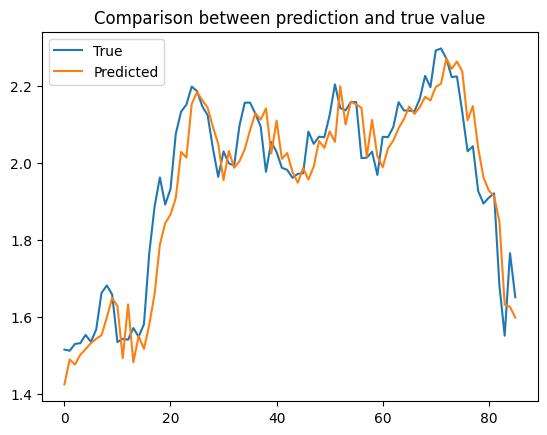

In [225]:
plot_predictions(preds_LSTM, actuals_LSTM)

## **Comparison**

In [263]:
predictions_results = {'GAN': preds_GAN, 'LSTM': preds_LSTM}

In [264]:
def plot_predictions_comparison(models_predictions, actuals):
  plt.plot(actuals, label='True')

  for (model, preds) in models_predictions.items():
    plt.plot(preds, label=model)

  plt.legend()
  plt.title('Comparison between prediction and true value')
  plt.show()

In [265]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# prendo nuovamente i dati

df_company, company_closings = get_dataframe(df, ['AAPL'])
df_company, company_closings = pd.DataFrame(scaler.fit_transform(df_company), columns=df_company.columns, index=df_company.index), pd.DataFrame(scaler.fit_transform(company_closings), columns=company_closings.columns, index=company_closings.index)

length = len(df_company)
split_idx = int(length * 0.9)

df_company_train = df_company.iloc[:split_idx]
df_company_closings_train = company_closings.iloc[:split_idx]
df_company_test = df_company.iloc[split_idx:]
df_company_closings_test = company_closings.iloc[split_idx:]

X_train = df_company_train.to_numpy().astype(np.float32)
y_train = df_company_closings_train.to_numpy().astype(np.float32)
X_test = df_company_test.to_numpy().astype(np.float32)
y_test = df_company_closings_test.to_numpy().astype(np.float32)

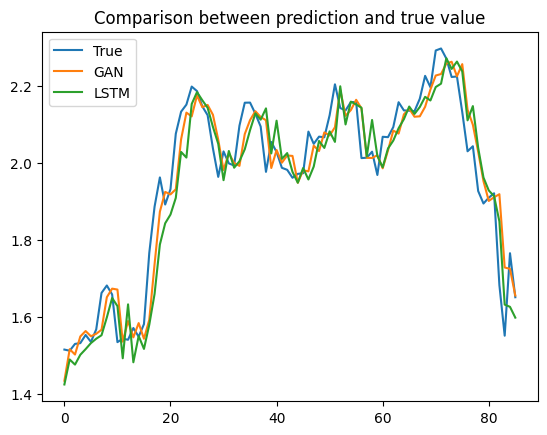

In [268]:
plot_predictions_comparison(predictions_results, y_test[40:])